In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHART_DIR = OUTPUT_DIR / "charts"

CHART_DIR.mkdir(parents=True, exist_ok=True)

# Load validated rankings
batting = pd.read_csv(OUTPUT_DIR / "batting_rankings.csv")
bowling = pd.read_csv(OUTPUT_DIR / "bowling_rankings.csv")

print("Batting rankings:", batting.shape)
print("Bowling rankings:", bowling.shape)
print("Available formats:", batting["competition_group"].unique())
print("Charts folder:", CHART_DIR)

Batting rankings: (20, 30)
Bowling rankings: (20, 32)
Available formats: <ArrowStringArray>
['IPL', 'T20I']
Length: 2, dtype: str
Charts folder: c:\Users\indra\OneDrive\Desktop\RR_super_selector\outputs\charts


In [4]:
import numpy as np

# Load all eligible players
bat_all = pd.read_csv(OUTPUT_DIR / "batting_all_eligible.csv")
bowl_all = pd.read_csv(OUTPUT_DIR / "bowling_all_eligible.csv")

# Combine each player's IPL and T20I performance
bat_combined = bat_all.groupby(
    ["striker_id", "striker_name"], as_index=False
).agg(
    pressure_runs=("pressure_runs", "sum"),
    pressure_balls=("pressure_balls", "sum"),
    pressure_dismissals=("pressure_dismissals", "sum"),
    pressure_matches=("pressure_matches", "sum"),
    normal_runs=("normal_runs", "sum"),
    normal_balls=("normal_balls", "sum"),
    normal_dismissals=("normal_dismissals", "sum"),
    normal_matches=("normal_matches", "sum")
)

bowl_combined = bowl_all.groupby(
    ["bowler_id", "bowler_name"], as_index=False
).agg(
    pressure_runs_conceded=("pressure_runs_conceded", "sum"),
    pressure_legal_balls=("pressure_legal_balls", "sum"),
    pressure_wickets=("pressure_wickets", "sum"),
    pressure_matches=("pressure_matches", "sum"),
    normal_runs_conceded=("normal_runs_conceded", "sum"),
    normal_legal_balls=("normal_legal_balls", "sum"),
    normal_wickets=("normal_wickets", "sum"),
    normal_matches=("normal_matches", "sum")
)

# Recalculate combined batting metrics
bat_combined["pressure_sr"] = (
    bat_combined["pressure_runs"] / bat_combined["pressure_balls"] * 100
)
bat_combined["pressure_avg"] = (
    bat_combined["pressure_runs"] /
    bat_combined["pressure_dismissals"].replace(0, np.nan)
)
bat_combined["normal_sr"] = (
    bat_combined["normal_runs"] / bat_combined["normal_balls"] * 100
)
bat_combined["sr_difference"] = (
    bat_combined["pressure_sr"] - bat_combined["normal_sr"]
)

# Recalculate combined bowling metrics
bowl_combined["pressure_economy"] = (
    bowl_combined["pressure_runs_conceded"] /
    bowl_combined["pressure_legal_balls"] * 6
)
bowl_combined["pressure_sr"] = (
    bowl_combined["pressure_legal_balls"] /
    bowl_combined["pressure_wickets"].replace(0, np.nan)
)
bowl_combined["normal_economy"] = (
    bowl_combined["normal_runs_conceded"] /
    bowl_combined["normal_legal_balls"] * 6
)
bowl_combined["economy_improvement"] = (
    bowl_combined["normal_economy"] -
    bowl_combined["pressure_economy"]
)

print("Combined batters:", len(bat_combined))
print("Combined bowlers:", len(bowl_combined))
print("\nBatting preview:")
display(bat_combined.head())
print("\nBowling preview:")
display(bowl_combined.head())

Combined batters: 108
Combined bowlers: 103

Batting preview:


,striker_id,striker_name,pressure_runs,pressure_balls,pressure_dismissals,pressure_matches,normal_runs,normal_balls,normal_dismissals,normal_matches,pressure_sr,pressure_avg,normal_sr,sr_difference
0,8,Mahendra Singh Dhoni,300.0,179.0,7.0,15.0,46.0,41.0,1.0,10.0,167.597765,42.857143,112.195122,55.402643
1,47,Virat Kohli,70.0,36.0,3.0,6.0,1403.0,924.0,21.0,32.0,194.444444,23.333333,151.839827,42.604618
2,126,Rohit Sharma,108.0,65.0,5.0,8.0,1032.0,725.0,32.0,37.0,166.153846,21.600000,142.344828,23.809019
3,143,Dinesh Karthik,205.0,114.0,7.0,9.0,133.0,75.0,2.0,10.0,179.824561,29.285714,177.333333,2.491228
4,152,Ravindra Jadeja,303.0,190.0,5.0,14.0,193.0,163.0,7.0,16.0,159.473684,60.600000,118.404908,41.068776



Bowling preview:


,bowler_id,bowler_name,pressure_runs_conceded,pressure_legal_balls,pressure_wickets,pressure_matches,normal_runs_conceded,normal_legal_balls,normal_wickets,normal_matches,pressure_economy,pressure_sr,normal_economy,economy_improvement
0,152,Ravindra Jadeja,219.0,147.0,11.0,13.0,685.0,512.0,16.0,32.0,8.938776,13.363636,8.027344,-0.911432
1,278,Tim Southee,165.0,117.0,12.0,10.0,361.0,271.0,15.0,17.0,8.461538,9.750000,7.992620,-0.468919
2,305,Ravichandran Ashwin,203.0,153.0,9.0,15.0,625.0,483.0,15.0,26.0,7.960784,17.000000,7.763975,-0.196809
3,360,Bhuvneshwar Kumar,588.0,344.0,17.0,29.0,999.0,790.0,40.0,47.0,10.255814,20.235294,7.587342,-2.668472
4,395,Karn Sharma,174.0,97.0,9.0,10.0,215.0,146.0,10.0,13.0,10.762887,10.777778,8.835616,-1.927270


In [5]:
# 1. Apply minimum sample requirements after combining formats

bat_final_pool = bat_combined[
    (bat_combined["pressure_balls"] >= 30) &
    (bat_combined["pressure_matches"] >= 5) &
    (bat_combined["normal_balls"] >= 30) &
    (bat_combined["normal_matches"] >= 5)
].copy()

bowl_final_pool = bowl_combined[
    (bowl_combined["pressure_legal_balls"] >= 60) &
    (bowl_combined["pressure_matches"] >= 5) &
    (bowl_combined["normal_legal_balls"] >= 60) &
    (bowl_combined["normal_matches"] >= 5) &
    (bowl_combined["pressure_wickets"] > 0)
].copy()

# 2. Batting score: original weights
bat_metrics = {
    "pressure_sr": 0.25,
    "pressure_avg": 0.15,
    "sr_difference": 0.20,
    "pressure_runs": 0.20,
    "pressure_matches": 0.10,
    "pressure_balls": 0.10
}

bat_final_pool["final_score"] = 0

for metric, weight in bat_metrics.items():
    percentile = bat_final_pool[metric].rank(pct=True)
    bat_final_pool["final_score"] += percentile * weight * 100

# 3. Bowling score: original weights
bowl_metrics = {
    "pressure_economy": (0.25, False),
    "economy_improvement": (0.20, True),
    "pressure_sr": (0.20, False),
    "pressure_wickets": (0.20, True),
    "pressure_matches": (0.10, True),
    "pressure_legal_balls": (0.05, True)
}

bowl_final_pool["final_score"] = 0

for metric, (weight, higher_is_better) in bowl_metrics.items():
    percentile = bowl_final_pool[metric].rank(
        pct=True, ascending=higher_is_better
    )
    bowl_final_pool["final_score"] += percentile * weight * 100

# 4. Select exactly 10 from each combined pool
final_batters = (
    bat_final_pool.sort_values("final_score", ascending=False)
    .head(10).copy()
)
final_bowlers = (
    bowl_final_pool.sort_values("final_score", ascending=False)
    .head(10).copy()
)

final_batters.insert(0, "rank", range(1, len(final_batters) + 1))
final_bowlers.insert(0, "rank", range(1, len(final_bowlers) + 1))

print("Eligible combined batters:", len(bat_final_pool))
print("Eligible combined bowlers:", len(bowl_final_pool))

print("\nFINAL TOP 10 BATTERS")
display(final_batters[[
    "rank", "striker_name", "final_score",
    "pressure_runs", "pressure_sr", "pressure_matches"
]])

print("\nFINAL TOP 10 BOWLERS")
display(final_bowlers[[
    "rank", "bowler_name", "final_score",
    "pressure_wickets", "pressure_economy", "pressure_matches"
]])

Eligible combined batters: 108
Eligible combined bowlers: 103

FINAL TOP 10 BATTERS


,rank,striker_name,final_score,pressure_runs,pressure_sr,pressure_matches
60,1,Rinku Singh,91.666667,373.0,198.404255,13.0
16,2,David Miller,91.388889,643.0,181.126761,27.0
102,3,Tristan Stubbs,90.231481,466.0,179.230769,18.0
93,4,Dhruv Jurel,87.777778,259.0,205.555556,12.0
87,5,Sherfane Rutherford,87.546296,457.0,182.800000,19.0
98,6,Namboori Tilak Varma,86.990741,640.0,175.342466,24.0
80,7,Tim David,85.324074,460.0,200.873362,23.0
99,8,Ashutosh Sharma,83.194444,248.0,200.000000,12.0
30,9,Marcus Stoinis,82.361111,404.0,177.973568,15.0
25,10,Dasun Shanaka,80.509259,251.0,181.884058,15.0



FINAL TOP 10 BOWLERS


,rank,bowler_name,final_score,pressure_wickets,pressure_economy,pressure_matches
23,1,Mohammad Nawaz,85.873786,15.0,5.135135,11.0
32,2,Mohit Sharma,84.563107,19.0,7.962963,11.0
57,3,Shadab Khan,83.616505,15.0,6.408163,13.0
101,4,Eshan Malinga,80.097087,16.0,7.958333,8.0
26,5,Adam Zampa,78.252427,15.0,7.884298,13.0
16,6,Yuzvendra Chahal,78.106796,35.0,8.335878,30.0
71,7,Arshdeep Singh,77.718447,44.0,8.639175,49.0
33,8,Jasprit Bumrah,76.796117,16.0,6.712329,22.0
50,9,Prasidh Krishna,75.388350,13.0,7.293413,15.0
93,10,Matheesha Pathirana,73.203883,16.0,7.990521,12.0


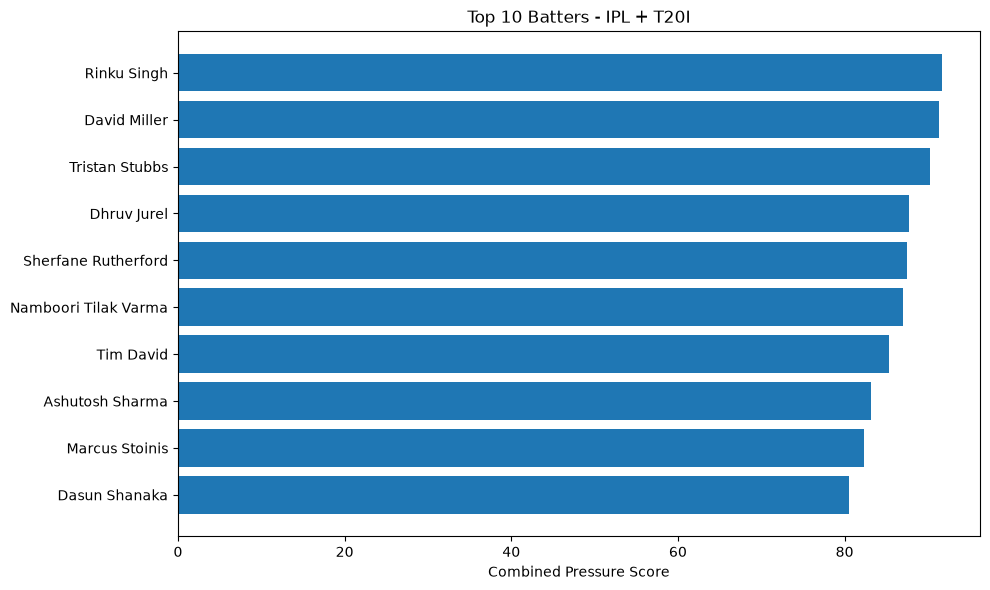

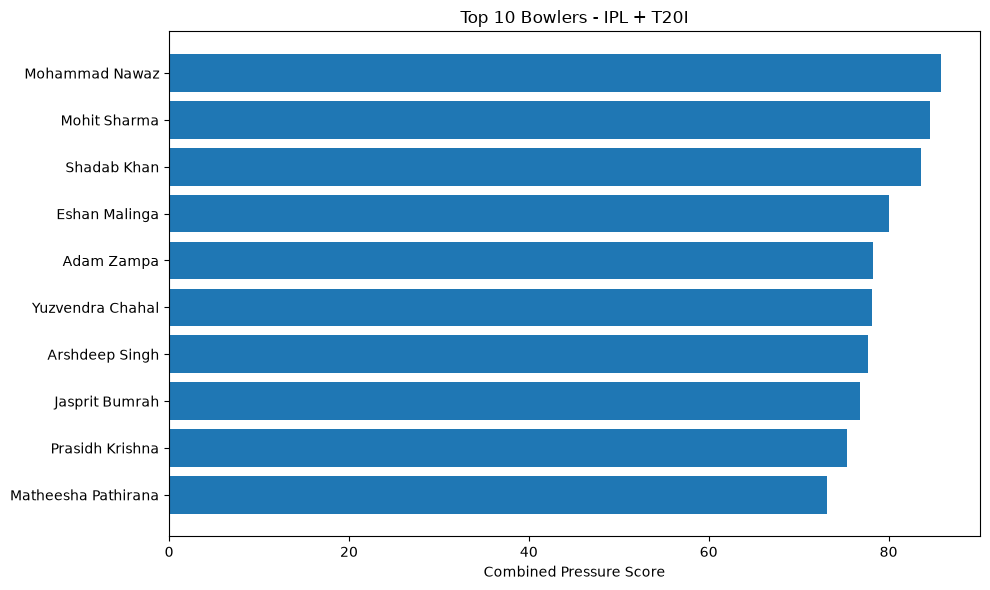

FINAL FILES SAVED
Batters: c:\Users\indra\OneDrive\Desktop\RR_super_selector\outputs\final_top_10_batters.csv
Bowlers: c:\Users\indra\OneDrive\Desktop\RR_super_selector\outputs\final_top_10_bowlers.csv
Charts: c:\Users\indra\OneDrive\Desktop\RR_super_selector\outputs\charts


In [6]:
# Save final ranking CSV files
final_batters.to_csv(
    OUTPUT_DIR / "final_top_10_batters.csv", index=False
)

final_bowlers.to_csv(
    OUTPUT_DIR / "final_top_10_bowlers.csv", index=False
)

# Top 10 batters graph
plt.figure(figsize=(10, 6))
b = final_batters.sort_values("final_score")

plt.barh(b["striker_name"], b["final_score"])
plt.xlabel("Combined Pressure Score")
plt.title("Top 10 Batters - IPL + T20I")
plt.tight_layout()
plt.savefig(CHART_DIR / "final_top_10_batters.png", dpi=300)
plt.show()
plt.close()

# Top 10 bowlers graph
plt.figure(figsize=(10, 6))
b = final_bowlers.sort_values("final_score")

plt.barh(b["bowler_name"], b["final_score"])
plt.xlabel("Combined Pressure Score")
plt.title("Top 10 Bowlers - IPL + T20I")
plt.tight_layout()
plt.savefig(CHART_DIR / "final_top_10_bowlers.png", dpi=300)
plt.show()
plt.close()

print("FINAL FILES SAVED")
print("Batters:", OUTPUT_DIR / "final_top_10_batters.csv")
print("Bowlers:", OUTPUT_DIR / "final_top_10_bowlers.csv")
print("Charts:", CHART_DIR)

In [7]:
from pathlib import Path
import pandas as pd

files = {
    "Batters": OUTPUT_DIR / "final_top_10_batters.csv",
    "Bowlers": OUTPUT_DIR / "final_top_10_bowlers.csv",
    "Batters graph": CHART_DIR / "final_top_10_batters.png",
    "Bowlers graph": CHART_DIR / "final_top_10_bowlers.png"
}

for name, path in files.items():
    print(name, ":", "EXISTS" if path.exists() else "MISSING")

bat_check = pd.read_csv(files["Batters"])
bowl_check = pd.read_csv(files["Bowlers"])

print("\nBatters:", len(bat_check))
print("Bowlers:", len(bowl_check))
print("Missing batting scores:", bat_check["final_score"].isna().sum())
print("Missing bowling scores:", bowl_check["final_score"].isna().sum())
print("Batting ranks:", sorted(bat_check["rank"].tolist()))
print("Bowling ranks:", sorted(bowl_check["rank"].tolist()))

Batters : EXISTS
Bowlers : EXISTS
Batters graph : EXISTS
Bowlers graph : EXISTS

Batters: 10
Bowlers: 10
Missing batting scores: 0
Missing bowling scores: 0
Batting ranks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Bowling ranks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
